# **What Is Associated with Heart Disease? An Exploratory and Predictive Analysis of 100,000 Patient Records**

**Subtitle: Python Bootcamp Assignment**

* Author: Phuc Vinh NGUYEN , Le Hoai An NGUYEN, UZUNLAR BATUHAN
* Instructor: Nafe MORADKHANI
* Date: November 2026

Dataset: Heart Disease Prediction Dataset 2026  | https://github.com/mohan13krishna/Heart-Disease-Prediction-Dataset-2026

# I. Introduction

## 1.1 Objectives
- Explore key factors (such as age and lifestyle behaviors like smoking and physical activity) associated with heart disease.
- Build a straightforward predictive model for heart disease.
- Provide practical insights to help raise awareness and prevent heart disease.

## 1.2 Research questions and Hypotheses
- **Research Question:** Which factors are most strongly associated with heart disease in this dataset?
- **Hypotheses:**
  - **H1:** Smokers have a significantly higher heart disease rate than non-smokers.
  - **H2:** Higher physical activity is associated with a lower rate of heart disease.

# II. Data Description & Preparation

## 2.1 Dataset overview

In [1]:
# Load dataset
import pandas as pd
df = pd.read_csv("heart_disease_prediction_2026.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (100000, 26)


,age,sex,bmi,region,income_level,smoking_status,alcohol_intake,physical_activity,diet_quality,sleep_hours,...,cholesterol,fasting_blood_sugar,max_heart_rate,resting_ecg,exercise_angina,st_depression,st_slope,avg_resting_hr,hrv_score,heart_disease
0,57,Male,27.1,Northeast,Middle,Never,Moderate,Light,7,5.7,...,204,0,195,Normal,0,0.9,Downsloping,61.8,19.9,0
1,40,Female,29.0,Northeast,Low,Never,Non-drinker,Sedentary,1,8.0,...,173,0,165,ST-T Abnormality,0,0.5,Downsloping,53.2,48.3,0
2,63,Female,40.1,Southeast,High,Never,Moderate,Sedentary,6,5.5,...,209,0,173,Normal,0,2.3,Downsloping,82.3,5.0,1
3,66,Female,35.5,West,Middle,Never,Heavy,Sedentary,10,7.4,...,187,0,144,Normal,0,1.3,Downsloping,71.1,38.3,1
4,29,Female,19.8,Northeast,High,Current,Non-drinker,Sedentary,8,8.3,...,247,0,170,ST-T Abnormality,0,0.4,Downsloping,74.1,49.4,0


This project uses the Heart Disease Prediction Dataset 2026, published on Kaggle. It contains 100,000 patient records with 25 predictor variables and one binary target, heart_disease (1 = disease present, 0 = absent). The target is fairly balanced: 46,082 positive cases (46.1%) and 53,918 negative cases (53.9%).

The predictors fall into five groups (Table 1).

**Table 1.** Grouping of the 25 predictor variables by clinical domain

| Group | Columns | Type |
|---|---|---|
| Demographics | `age`, `sex`, `region`, `income_level` | numeric / categorical |
| Lifestyle | `smoking_status`, `alcohol_intake`, `physical_activity`, `diet_quality`, `sleep_hours`, `stress_level` | categorical / ordinal (1-10) / numeric |
| Medical history | `diabetes`, `hypertension`, `family_history`, `previous_heart_event` | binary (0/1) |
| Clinical measures | `resting_bp`, `cholesterol`, `fasting_blood_sugar`, `bmi` | numeric / binary |
| Cardiac tests | `max_heart_rate`, `resting_ecg`, `exercise_angina`, `st_depression`, `st_slope`, `avg_resting_hr`, `hrv_score` | numeric / categorical / binary |

In [2]:
# Data overview
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   age                   100000 non-null  int64  
 1   sex                   100000 non-null  str    
 2   bmi                   100000 non-null  float64
 3   region                100000 non-null  str    
 4   income_level          100000 non-null  str    
 5   smoking_status        100000 non-null  str    
 6   alcohol_intake        100000 non-null  str    
 7   physical_activity     100000 non-null  str    
 8   diet_quality          100000 non-null  int64  
 9   sleep_hours           100000 non-null  float64
 10  stress_level          100000 non-null  int64  
 11  diabetes              100000 non-null  int64  
 12  hypertension          100000 non-null  int64  
 13  family_history        100000 non-null  int64  
 14  previous_heart_event  100000 non-null  int64  
 15  resting_bp  

In [3]:
print(df.dtypes.value_counts())

int64      13
str         8
float64     5
Name: count, dtype: int64


The dataset contains 100,000 rows and 26 columns.

- 13 columns are stored as integers
- 5 columns are float
- 8 columns are text (categorical)

However, several integer columns are in fact binary flags (e.g., `diabetes`, `hypertension`) or ordinal 1-10 scores (`diet_quality`, `stress_level`), and they are interpreted accordingly in the analysis.

In [4]:
df.describe()

,age,bmi,diet_quality,sleep_hours,stress_level,diabetes,hypertension,family_history,previous_heart_event,resting_bp,cholesterol,fasting_blood_sugar,max_heart_rate,exercise_angina,st_depression,avg_resting_hr,hrv_score,heart_disease
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,53.497760,28.063562,5.824270,6.909246,5.728600,0.110030,0.469870,0.301430,0.030140,142.063750,217.672840,0.142200,174.253570,0.256500,1.391536,70.032455,52.789298,0.460820
std,12.448859,5.462485,2.012782,1.091675,2.190189,0.312929,0.499094,0.458881,0.170973,25.082072,48.202876,0.349257,14.793637,0.436703,1.050935,12.507142,19.380486,0.498465
min,29.000000,15.000000,1.000000,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,80.000000,100.000000,0.000000,107.000000,0.000000,0.000000,40.000000,5.000000,0.000000
25%,45.000000,24.300000,4.000000,6.200000,4.000000,0.000000,0.000000,0.000000,0.000000,124.000000,185.000000,0.000000,164.000000,0.000000,0.600000,61.500000,39.500000,0.000000
50%,53.000000,28.000000,6.000000,6.900000,6.000000,0.000000,0.000000,0.000000,0.000000,141.000000,218.000000,0.000000,174.000000,0.000000,1.100000,70.000000,52.900000,0.000000
75%,62.000000,31.700000,7.000000,7.600000,7.000000,0.000000,1.000000,1.000000,0.000000,160.000000,251.000000,0.000000,185.000000,1.000000,2.000000,78.500000,66.000000,1.000000
max,80.000000,54.600000,10.000000,10.000000,10.000000,1.000000,1.000000,1.000000,1.000000,200.000000,400.000000,1.000000,202.000000,1.000000,6.200000,110.000000,100.000000,1.000000


**Table 2.** Summary statistics of the nine continuous variables
| Variable | Mean | Std | Min | Median | Max |
|---|---|---|---|---|---|
| `age` | 53.5 | 12.4 | 29 | 53 | 80 |
| `bmi` | 28.1 | 5.5 | 15.0 | 28.0 | 54.6 |
| `sleep_hours` | 6.9 | 1.1 | 4.0 | 6.9 | 10.0 |
| `resting_bp` | 142.1 | 25.1 | 80 | 141 | 200 |
| `cholesterol` | 217.7 | 48.2 | 100 | 218 | 400 |
| `max_heart_rate` | 174.3 | 14.8 | 107 | 174 | 202 |
| `st_depression` | 1.39 | 1.05 | 0.0 | 1.10 | 6.2 |
| `avg_resting_hr` | 70.0 | 12.5 | 40 | 70.0 | 110 |
| `hrv_score` | 52.8 | 19.4 | 5.0 | 52.9 | 100 |


Patients are on average 53.5 years old (range 29-80).

- Mean BMI is 28.1
- Mean resting systolic blood pressure is 142.1 mmHg
- Mean cholesterol is 217.7 mg/dL.

Among the binary indicators,
- 47.0% of patients have hypertension,
- 30.1% have a family history of heart disease,
- 25.7% have exercise-induced angina,
- 14.2% have elevated fasting blood sugar,
- 11.0% have diabetes, and
- 3.0% have had a previous heart event.

-> Most numeric variables are roughly symmetric (mean close to median), with the exception of ST depression, which is right-skewed (mean 1.39, median 1.10, maximum 6.2).

#### **Exploring and summarizing the distribution of categorical features**
- Identify all categorical columns in the dataset.
- Analyze the frequency and percentage distribution of categories (e.g., smoking status, region, sex).
- Verify data consistency before moving into deep exploratory analysis.

In [5]:
cat_cols = df.select_dtypes(exclude="number").columns

for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


sex:
sex
Male      55176
Female    44824
Name: count, dtype: int64

region:
region
Southeast    25087
Midwest      21956
Northeast    18103
West         17885
Southwest    16969
Name: count, dtype: int64

income_level:
income_level
Middle    45006
Low       30147
High      24847
Name: count, dtype: int64

smoking_status:
smoking_status
Never      61887
Former     24182
Current    13931
Name: count, dtype: int64

alcohol_intake:
alcohol_intake
Moderate       48038
Non-drinker    37898
Heavy          14064
Name: count, dtype: int64

physical_activity:
physical_activity
Sedentary      29715
Light          28303
Active         24392
Very Active    17590
Name: count, dtype: int64

resting_ecg:
resting_ecg
Normal                          45940
ST-T Abnormality                35486
Left Ventricular Hypertrophy    18574
Name: count, dtype: int64

st_slope:
st_slope
Upsloping      42769
Flat           38594
Downsloping    18637
Name: count, dtype: int64


**Table 3.** Distribution of the eight categorical variables (percentage of 100,000 patients)
| Variable | Distribution in the dataset |
|---|---|
| `sex` | Male 55.2% · Female 44.8% |
| `region` | Southeast 25.1% · Midwest 22.0% · Northeast 18.1% · West 17.9% · Southwest 17.0% |
| `income_level` | Middle 45.0% · Low 30.1% · High 24.8% |
| `smoking_status` | Never 61.9% · Former 24.2% · Current 13.9% |
| `alcohol_intake` | Moderate 48.0% · Non-drinker 37.9% · Heavy 14.1% |
| `physical_activity` | Sedentary 29.7% · Light 28.3% · Active 24.4% · Very Active 17.6% |
| `resting_ecg` | Normal 45.9% · ST-T Abnormality 35.5% · LVH 18.6% |
| `st_slope` | Upsloping 42.8% · Flat 38.6% · Downsloping 18.6% |

*LVH = Left Ventricular Hypertrophy.*

The sample is slightly male-dominated (55.2%) and spread fairly evenly across the five regions (17.0-25.1%).
- Most patients have never smoked (61.9%), while 38.1% are current or former smokers.
- Lifestyle categories are also unevenly distributed: 29.7% of patients are leading a sedentary lifestyle and 14.1% report heavy alcohol intake.
- On the ECG side, 45.9% of resting ECGs are normal, and left ventricular hypertrophy is the least common finding (18.6%).

Although some categories are much larger than others, even the smallest one (current smokers, n = 13,931) contains well over 10,000 patients, so all groups are large enough for reliable comparison and none needed to be merged. Because the groups differ in size, later sections compare disease *rates* within each group rather than raw counts.

## 2.2 Data quality checks


In [6]:
# CHECK FOR LABEL PROBLEMS (extra whitespace, or the same label written in different cases)
for col in cat_cols:
    s = df[col]
    print(col, "| extra whitespace:", (s != s.str.strip()).sum(),
          "| unique labels:", s.nunique(),
          "| unique labels after lowercasing:", s.str.lower().nunique())

sex | extra whitespace: 0 | unique labels: 2 | unique labels after lowercasing: 2
region | extra whitespace: 0 | unique labels: 5 | unique labels after lowercasing: 5
income_level | extra whitespace: 0 | unique labels: 3 | unique labels after lowercasing: 3
smoking_status | extra whitespace: 0 | unique labels: 3 | unique labels after lowercasing: 3
alcohol_intake | extra whitespace: 0 | unique labels: 3 | unique labels after lowercasing: 3
physical_activity | extra whitespace: 0 | unique labels: 4 | unique labels after lowercasing: 4
resting_ecg | extra whitespace: 0 | unique labels: 3 | unique labels after lowercasing: 3
st_slope | extra whitespace: 0 | unique labels: 3 | unique labels after lowercasing: 3


The eight categorical variables were checked for leading or trailing whitespace and for labels that differ only in capitalization. No extra whitespace was found, and the number of unique labels did not change after converting to lowercase for any variable (2-5 labels per variable). The labels are therefore clean and consistent, and no recoding was required.

In [7]:
# CHECK MISSING VALUES AND DUPLICATES
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicates: {df.duplicated().sum()}")

Missing values: 0
Duplicates: 0


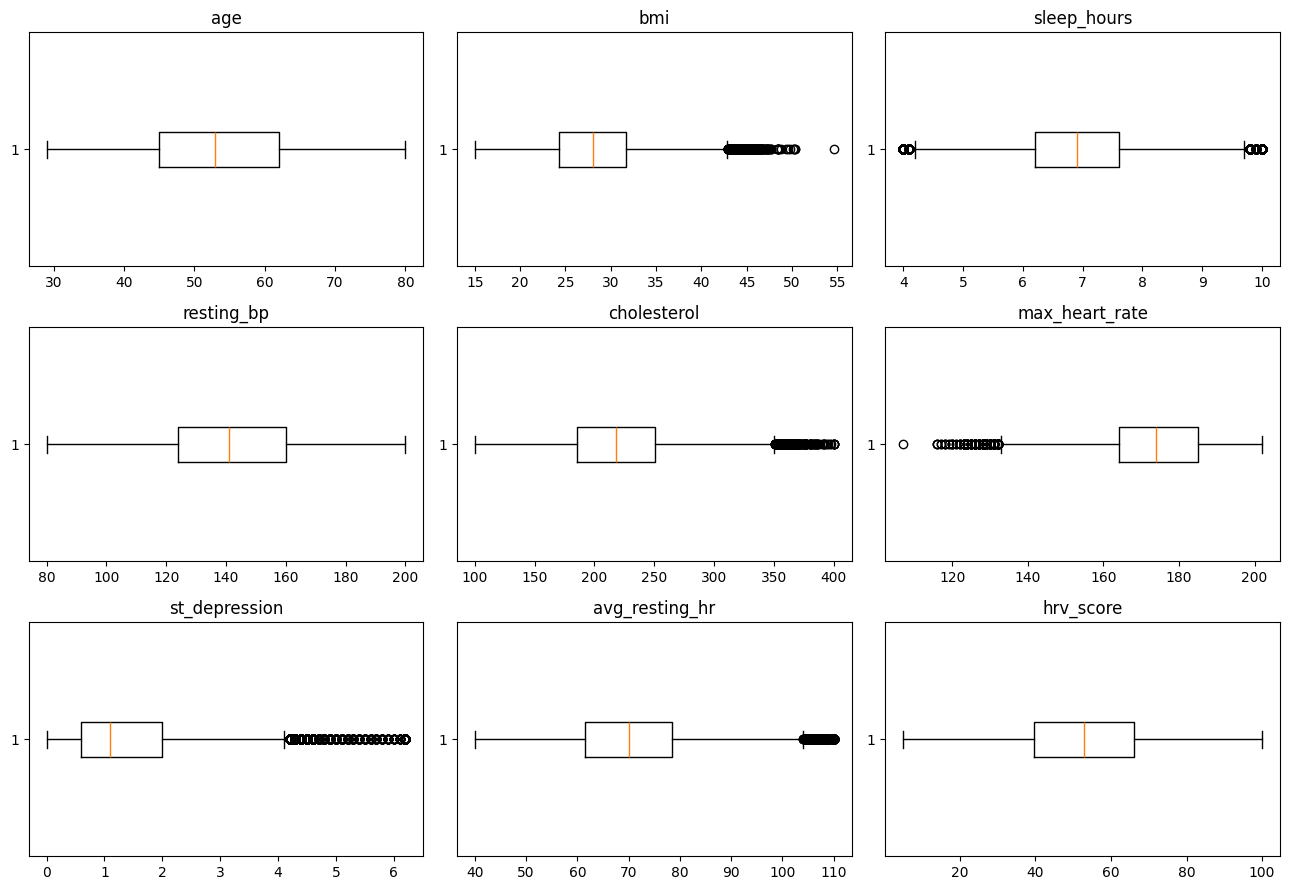

In [8]:
# CHECK OUTLIER
# List of the 9 continuous variables we want to check
num = [
    "age", "bmi", "sleep_hours", "resting_bp", "cholesterol",
    "max_heart_rate", "st_depression", "avg_resting_hr", "hrv_score"
]
import matplotlib.pyplot as plt

# Create a 3x3 grid of empty charts, total size 13x9 inches
# figsize = (width, height) of the whole figure in inches
fig, axes = plt.subplots(3, 3, figsize=(13, 9))

# axes is a 3x3 grid; flatten() turns it into a simple list of 9 charts
# zip() pairs each chart with one variable name: (chart 1, "age"), (chart 2, "bmi"), ...
for ax, c in zip(axes.flatten(), num):

    # Draw a horizontal boxplot (vert=False) of column c on this chart
    ax.boxplot(df[c], vert=False)

    # Use the variable name as the chart title
    ax.set_title(c)

# Adjust spacing so the charts do not overlap, then display the figure
plt.tight_layout();
plt.show()

**Figure 1.** Boxplots of the nine continuous variables. Points beyond the whiskers are flagged by the 1.5 × IQR rule.

Figure 1 confirms that the flagged values mostly lie on one side of the distribution (high BMI, cholesterol, ST depression and resting heart rate; low maximum heart rate), with sleep hours the only variable flagged on both sides. Age, resting blood pressure and HRV score show no outliers.

In [9]:
num = ["age", "bmi", "sleep_hours", "resting_bp", "cholesterol",
       "max_heart_rate", "st_depression", "avg_resting_hr", "hrv_score"]

# Loop over each of the 9 continuous variables in the list above
for col in num:
    # Count how many patients have each value of this column,
    # then sort by the value itself (smallest to largest) instead of by count
    # Result: index = value, number = how many patients have that value
    s = df[col].value_counts().sort_index()

    # Print one line per variable:
    #   {col:<14}        -> variable name, left-aligned in 14 characters so lines line up for reading easily
    #   s.head(3)        -> the 3 smallest values and their counts
    #   s.tail(3)        -> the 3 largest values and their counts
    #   .to_dict()       -> show them as {value: count} in dictionary
    print(f"{col:14} | Min values: {s.head(3).to_dict()} | Max values: {s.tail(3).to_dict()}")

age            | Min values: {29: 3271, 30: 591, 31: 775} | Max values: {78: 542, 79: 470, 80: 2326}
bmi            | Min values: {15.0: 904, 15.1: 46, 15.2: 54} | Max values: {50.2: 1, 50.3: 2, 54.6: 1}
sleep_hours    | Min values: {4.0: 448, 4.1: 118, 4.2: 213} | Max values: {9.8: 139, 9.9: 79, 10.0: 282}
resting_bp     | Min values: {80: 358, 81: 45, 82: 67} | Max values: {198: 148, 199: 160, 200: 1146}
cholesterol    | Min values: {100: 892, 101: 50, 102: 43} | Max values: {397: 1, 398: 1, 400: 5}
max_heart_rate | Min values: {107: 1, 116: 3, 117: 2} | Max values: {200: 633, 201: 597, 202: 3754}
st_depression  | Min values: {0.0: 2547, 0.1: 2405, 0.2: 3311} | Max values: {6.0: 18, 6.1: 18, 6.2: 149}
avg_resting_hr | Min values: {40.0: 898, 40.1: 19, 40.2: 23} | Max values: {109.7: 2, 109.8: 2, 110.0: 80}
hrv_score      | Min values: {5.0: 790, 5.1: 10, 5.2: 14} | Max values: {99.8: 14, 99.9: 12, 100.0: 841}


**Table 4.** Counts of patients at the lowest and highest values of each continuous variable

| Variable | Min value | n at min | n at next value | Max value | n at max | n at previous value |
|---|---|---|---|---|---|---|
| `age` | 29 | 3,271 | 591 | 80 | 2,326 | 470 |
| `bmi` | 15.0 | 904 | 46 | 54.6 | 1 | 2 |
| `sleep_hours` | 4.0 | 448 | 118 | 10.0 | 282 | 79 |
| `resting_bp` | 80 | 358 | 45 | 200 | 1,146 | 160 |
| `cholesterol` | 100 | 892 | 50 | 400 | 5 | 1 |
| `max_heart_rate` | 107 | 1 | 3 | 202 | 3,754 | 597 |
| `st_depression` | 0.0 | 2,547 | 2,405 | 6.2 | 149 | 18 |
| `avg_resting_hr` | 40.0 | 898 | 19 | 110.0 | 80 | 2 |
| `hrv_score` | 5.0 | 790 | 10 | 100.0 | 841 | 12 |

The data shows unusually high numbers of observations at certain boundary values. For example, 3,754 patients have a maximum heart rate of 202 bpm, compared with 597 at 201 bpm. Similarly, 3,271 patients are 29 years old, while only 591 are 30. These patterns are worth noting, although the data alone does not explain why they occur.

No observations were removed or modified during this step. The original values were kept for the subsequent analysis.

**Why do the data values cluster at the boundaries?**

This artificial boundary effect typically stems from two main reasons:

First, synthetic data generation: Researchers often use machine learning algorithms (like CTGAN or SMOTE variants) to expand medical datasets, which frequently leaves rigid, unnatural cut-offs at the extremes.

Second, clinical protocols or clipping: In practice, healthcare providers or data collectors sometimes apply top-coding and bottom-coding for patient privacy or to cap extreme physiological outliers for safety guidelines.

### 2.3 Feature engineering (age group, BMI category, blood pressure category)

This step groups age, BMI, and resting blood pressure into categories, making it easier to compare heart disease rates across different groups in the EDA section.

##### **Age Groups, BMI Categories, and Blood Pressure Categories**

**1. `age_group` — Age Groups**

- Age was divided into four groups: under 40, 40–54, 55–64, and 65+.
- **Purpose:** These groups make it easier to compare heart disease rates across different age ranges.

**2. `bmi_category` — BMI Categories**

- BMI was grouped into four categories: Underweight, Normal, Overweight, and Obese, according to World Health Organization (WHO) standards.
- **Purpose:** Grouping BMI makes it easier to compare heart disease rates across weight categories rather than individual BMI values.

**3. `bloodPressure_category` — Blood Pressure Categories**

- Resting blood pressure was divided into four categories: Normal, Elevated, High (stage 1), and High (stage 2), based on American Heart Association (AHA) thresholds.
- **Purpose:** These categories make it easier to examine how heart disease rates vary across blood pressure levels.

In [10]:
# Create columns for age group and BMI
df["age_group"] = pd.cut(df["age"],
                         bins=[0, 39, 54, 64, 120],
                         labels=["<40", "40-54", "55-64", "65+"])

df["bmi_category"] = pd.cut(df["bmi"],
                            bins=[0, 18.5, 25, 30, 100],
                            right=False,
                            labels=["Underweight", "Normal", "Overweight", "Obese"])

df["bloodPressure_category"] = pd.cut(df["resting_bp"],
                           bins=[0, 120, 130, 140, 1000],
                           right=False,
                           labels=["Normal", "Elevated", "High (stage 1)", "High (stage 2)"])

In [11]:
# Print them out to check whether they were created correctly
print(df["age_group"].value_counts())
print(df["bmi_category"].value_counts())
print(df["bloodPressure_category"].value_counts())

age_group
40-54    39249
55-64    26694
65+      19869
<40      14188
Name: count, dtype: int64
bmi_category
Obese          36412
Overweight     34852
Normal         24667
Underweight     4069
Name: count, dtype: int64
bloodPressure_category
High (stage 2)    52390
Normal            19439
High (stage 1)    14786
Elevated          13385
Name: count, dtype: int64


The group counts add up to 100,000 for all three engineered features, confirming that every observation was assigned to a category:

- **Age group:** 14,188 + 39,249 + 26,694 + 19,869 = 100,000
- **BMI category:** 4,069 + 24,667 + 34,852 + 36,412 = 100,000
- **Blood pressure category:** 19,439 + 13,385 + 14,786 + 52,390 = 100,000

### Summary

The largest age group was 40–54 (39.25%). Overweight and Obese patients together accounted for 71.26% of the dataset, while 52.39% fell into the High (stage 2) blood pressure category based on the selected thresholds.

These new categories will be used in the EDA section to compare heart disease rates across groups.

# III. Exploratory Data Analysis

In [12]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "axes.facecolor": "#f8f8f8",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "white",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})

BLUE = "#2979D6"
RED = "#E34A4A"

## 3.1 Distributions & comparisons by disease status


**Continuous variables by disease status.**

To investigate which clinical measurements shift most significantly in the presence of heart disease, Table/Summary comparison was evaluated across the two cohorts.

In [13]:
num = ["age", "bmi", "sleep_hours", "resting_bp", "cholesterol",
       "max_heart_rate", "st_depression", "avg_resting_hr", "hrv_score"]

summary = df.groupby("heart_disease")[num].mean().round(2).T
summary.columns = ["No disease", "Disease"]
summary["Difference"] = (summary["Disease"] - summary["No disease"]).round(2)
print(summary)

                No disease  Disease  Difference
age                  48.23    59.66       11.43
bmi                  27.30    28.96        1.66
sleep_hours           6.97     6.83       -0.14
resting_bp          134.60   150.80       16.20
cholesterol         210.91   225.58       14.67
max_heart_rate      178.61   169.15       -9.46
st_depression         1.07     1.77        0.70
avg_resting_hr       68.96    71.29        2.33
hrv_score            56.48    48.47       -8.01


Patients with heart disease were older on average (59.66 vs. 48.23 years) and had higher mean resting blood pressure (150.80 vs. 134.60 mmHg), cholesterol levels (225.58 vs. 210.91 mg/dL), and ST depression values (1.77 vs. 1.07).

They also had a lower mean maximum heart rate (169.15 vs. 178.61 bpm) and a lower mean HRV score (48.47 vs. 56.48). Smaller differences were observed in BMI (28.96 vs. 27.30), average resting heart rate (71.29 vs. 68.96 bpm), and sleep duration (6.83 vs. 6.97 hours).

Overall, age, resting blood pressure, cholesterol, ST depression, maximum heart rate, and HRV score showed more noticeable differences between the two groups in terms of their mean values. These descriptive comparisons do not establish causation or indicate whether the differences are statistically significant.

**Continuous variables by outcome.**


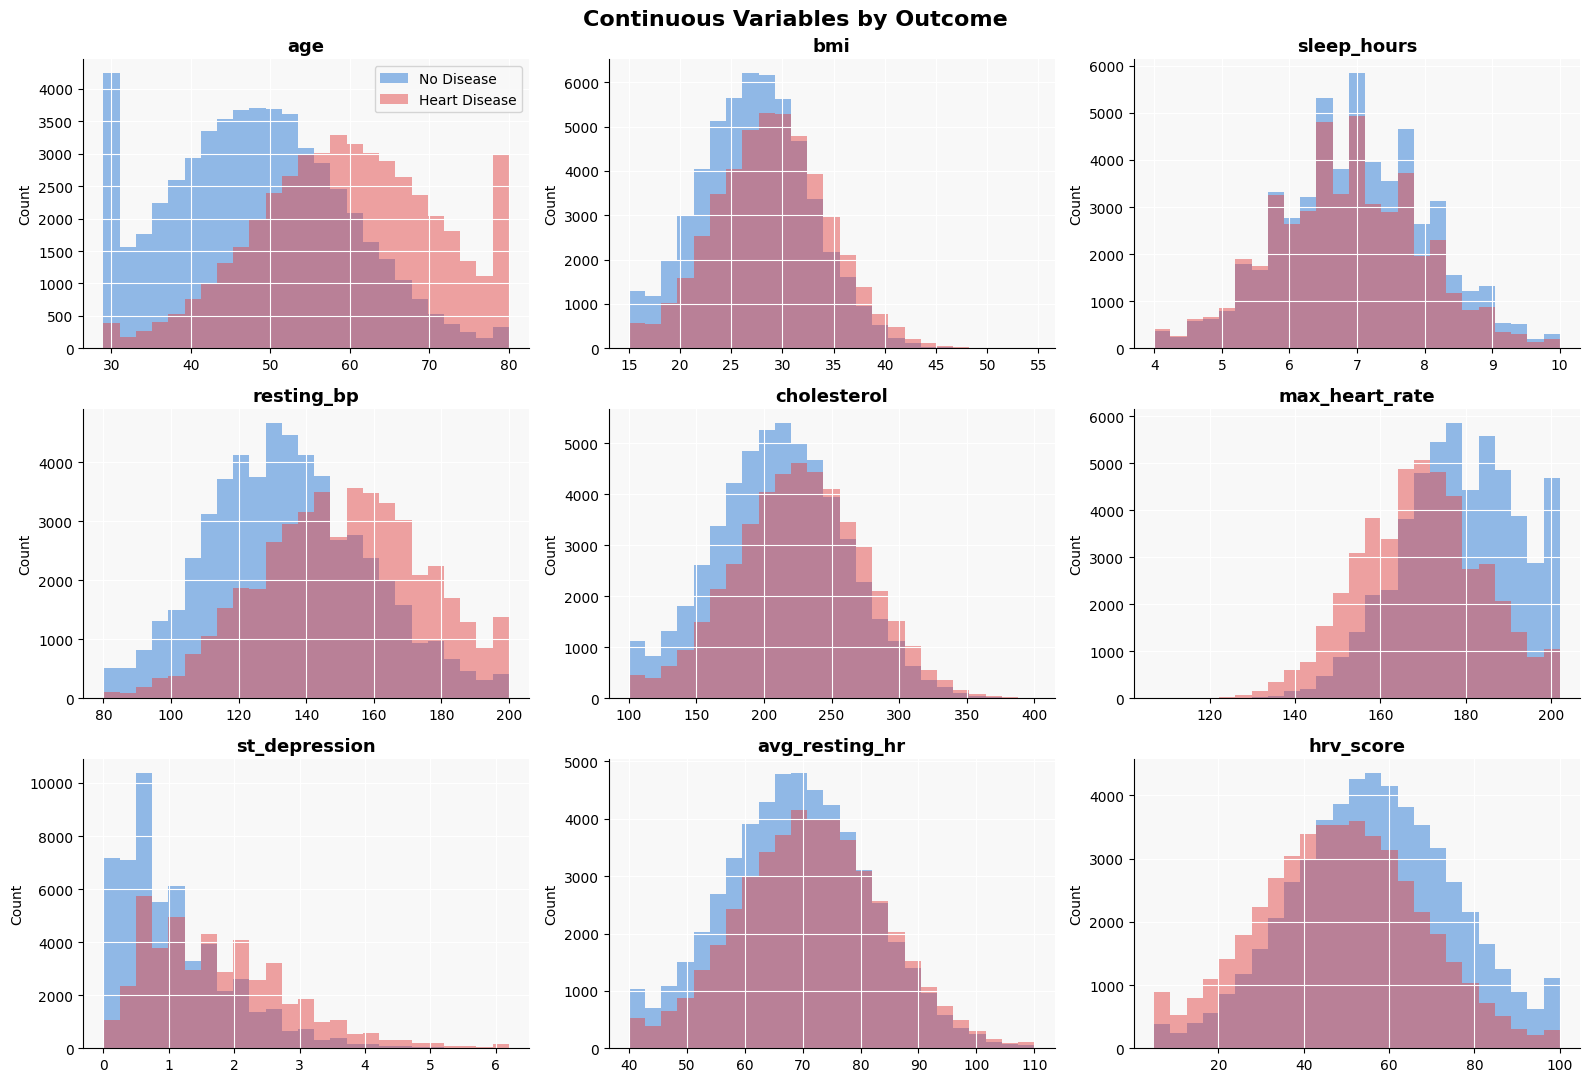

In [14]:
num = ["age", "bmi", "sleep_hours", "resting_bp", "cholesterol",
       "max_heart_rate", "st_depression", "avg_resting_hr", "hrv_score"]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.flatten()

for ax, col in zip(axes, num):
    bins = np.histogram_bin_edges(df[col], bins=25)
    ax.hist(df[df["heart_disease"] == 0][col], bins=bins, alpha=0.50, color=BLUE, label="No Disease")
    ax.hist(df[df["heart_disease"] == 1][col], bins=bins, alpha=0.50, color=RED, label="Heart Disease")
    ax.set_title(col)
    ax.set_ylabel("Count")

axes[0].legend()
fig.suptitle("Continuous Variables by Outcome", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

**Figure 2.** Distributions of continuous variables by heart disease status.

Figure 2 shows noticeable distributional differences between the two groups in age, resting blood pressure, ST depression, maximum heart rate, and HRV score. Patients with heart disease tend to have higher values for age, resting blood pressure, and ST depression, but lower values for maximum heart rate and HRV score. Cholesterol and BMI show more modest differences, while sleep hours and average resting heart rate have broadly similar distributions. However, the distributions overlap to varying degrees across all variables, suggesting that no single variable clearly distinguishes the two groups on its own.

**Heart disease rate by category**


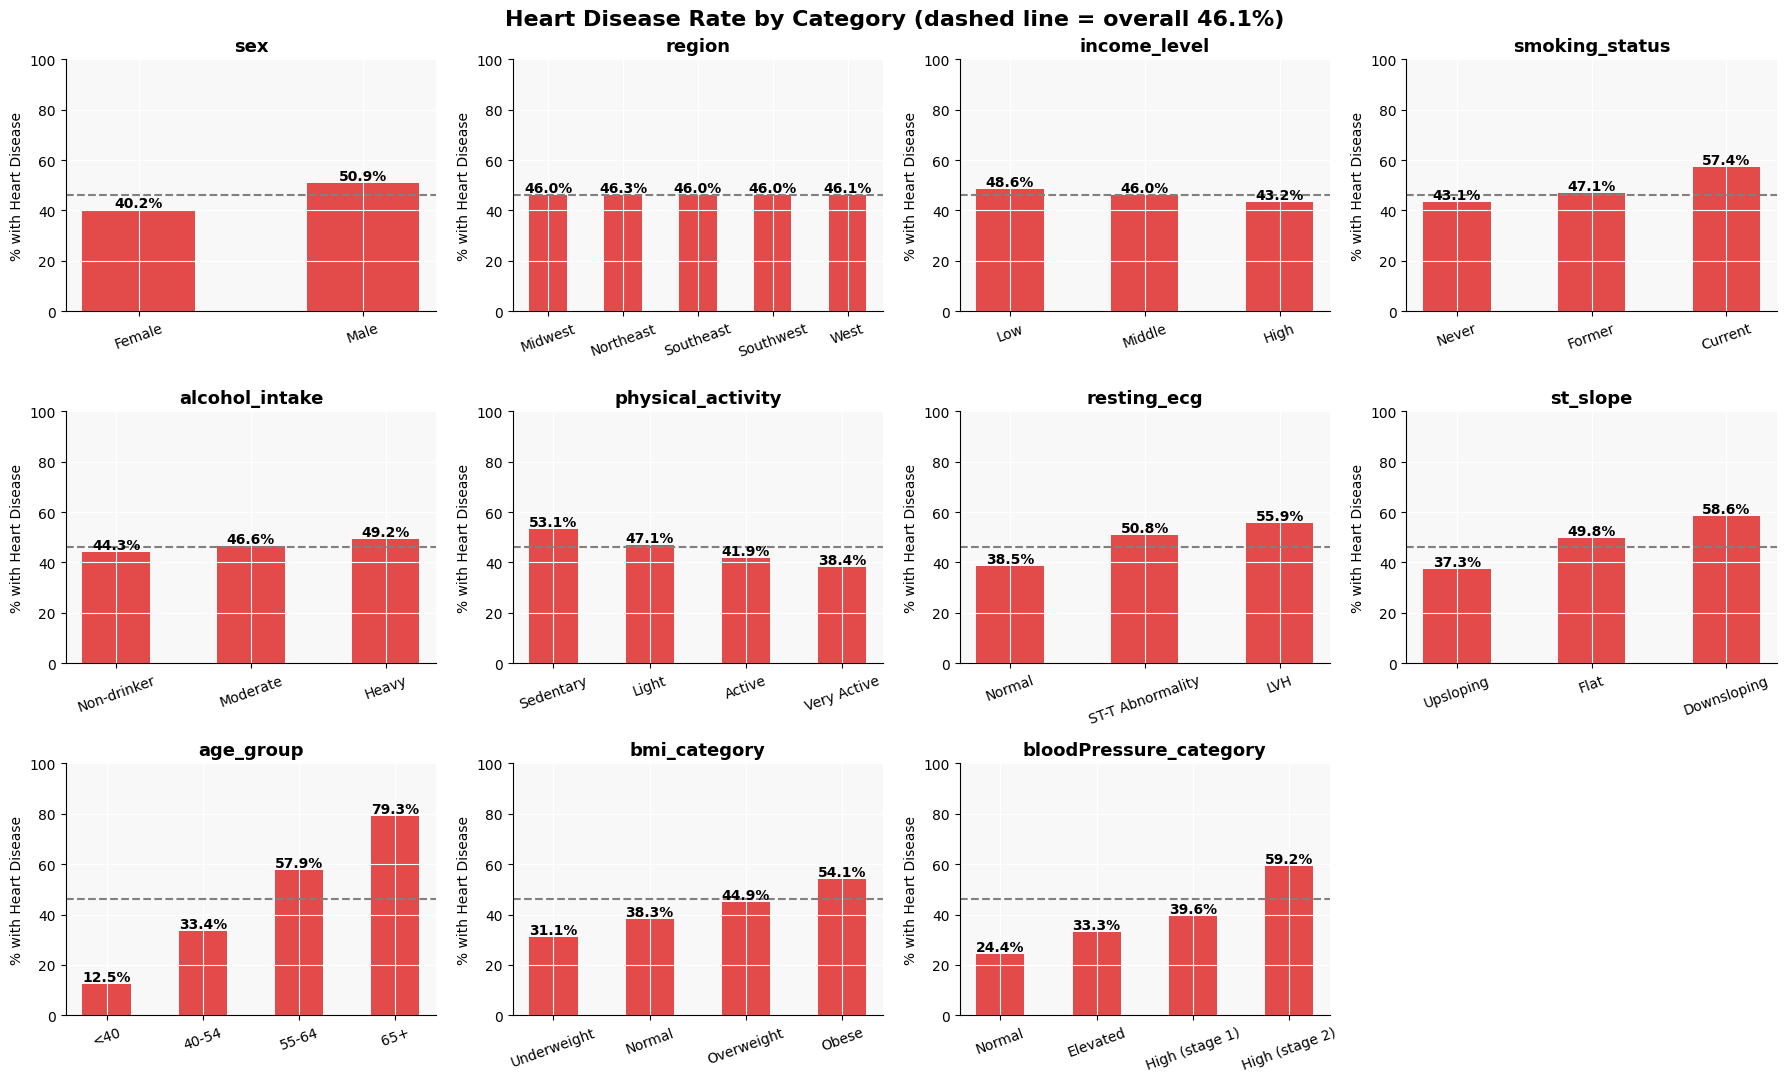

In [15]:
# List of variables to plot (8 original categorical + 3 columns created in 2.3)
cat_vars = ["sex", "region", "income_level", "smoking_status",
            "alcohol_intake", "physical_activity", "resting_ecg", "st_slope",
            "age_group", "bmi_category", "bloodPressure_category"]

# Order of the groups from low to high (sex and region have no natural order, so they are skipped)
order = {
    "income_level": ["Low", "Middle", "High"],
    "smoking_status": ["Never", "Former", "Current"],
    "alcohol_intake": ["Non-drinker", "Moderate", "Heavy"],
    "physical_activity": ["Sedentary", "Light", "Active", "Very Active"],
    "resting_ecg": ["Normal", "ST-T Abnormality", "Left Ventricular Hypertrophy"],
    "st_slope": ["Upsloping", "Flat", "Downsloping"],
}

overall = df["heart_disease"].mean() * 100         # Overall heart disease rate (46.1%)

fig, axes = plt.subplots(3, 4, figsize=(18, 11))   # Create a grid of 3 rows x 4 columns of charts
axes = axes.flatten()                              # Turn the grid into a simple list of 12 panels

for ax, col in zip(axes, cat_vars):                # One variable per panel
    rate = df.groupby(col, observed=True)["heart_disease"].mean() * 100   # Heart disease rate of each group
    if col in order:
        rate = rate.loc[order[col]]                # Reorder the groups from low to high
    labels = [str(x).replace("Left Ventricular Hypertrophy", "LVH") for x in rate.index]   # Shorten the long label

    bars = ax.bar(labels, rate.values, color=RED, width=0.5)    # Draw the bars
    ax.bar_label(bars, fmt="%.1f%%", fontweight="bold")         # Write the % value on top of each bar
    ax.axhline(overall, linestyle="--", color="gray")           # Dashed line = overall rate
    ax.set_title(col)                                           # Chart title = variable name
    ax.set_ylim(0, 100)                                         # Y-axis always from 0 to 100% to make sure it's consistent over 12 charts
    ax.set_ylabel("% with Heart Disease")
    ax.tick_params(axis="x", rotation=20)                       # Rotate the x labels so they do not overlap

axes[-1].axis("off")      # Hide the empty last panel (11 variables, 12 panels)
fig.suptitle("Heart Disease Rate by Category (dashed line = overall 46.1%)", fontsize=16, fontweight="bold")
plt.tight_layout()        # Prevent charts from overlapping
plt.show()

**Figure 3.** Heart disease rates across categorical variables.

Figure 3 shows substantial differences in heart disease rates across several categories. The clearest pattern appears in age groups, with the rate increasing from 12.5% among individuals under 40 to 79.3% among those aged 65 and above. A decreasing pattern is also observed across physical activity levels, from 53.1% among sedentary individuals to 38.4% among very active individuals. Heart disease rates also increase across the defined blood pressure categories, from 24.4% for the Normal group to 59.2% for High (stage 2). Current smokers have a higher observed rate (57.4%) than never-smokers (43.1%), while the rates also vary across BMI categories and resting ECG groups.

In contrast, heart disease rates are relatively similar across regions and income levels. Overall, these descriptive patterns suggest that age, physical activity, blood pressure category, smoking status, and ST slope are worth examining further. However, these comparisons do not account for potential confounding factors and do not establish causal relationships.

## 3.2 Correlation & interactions


### **Correlation**

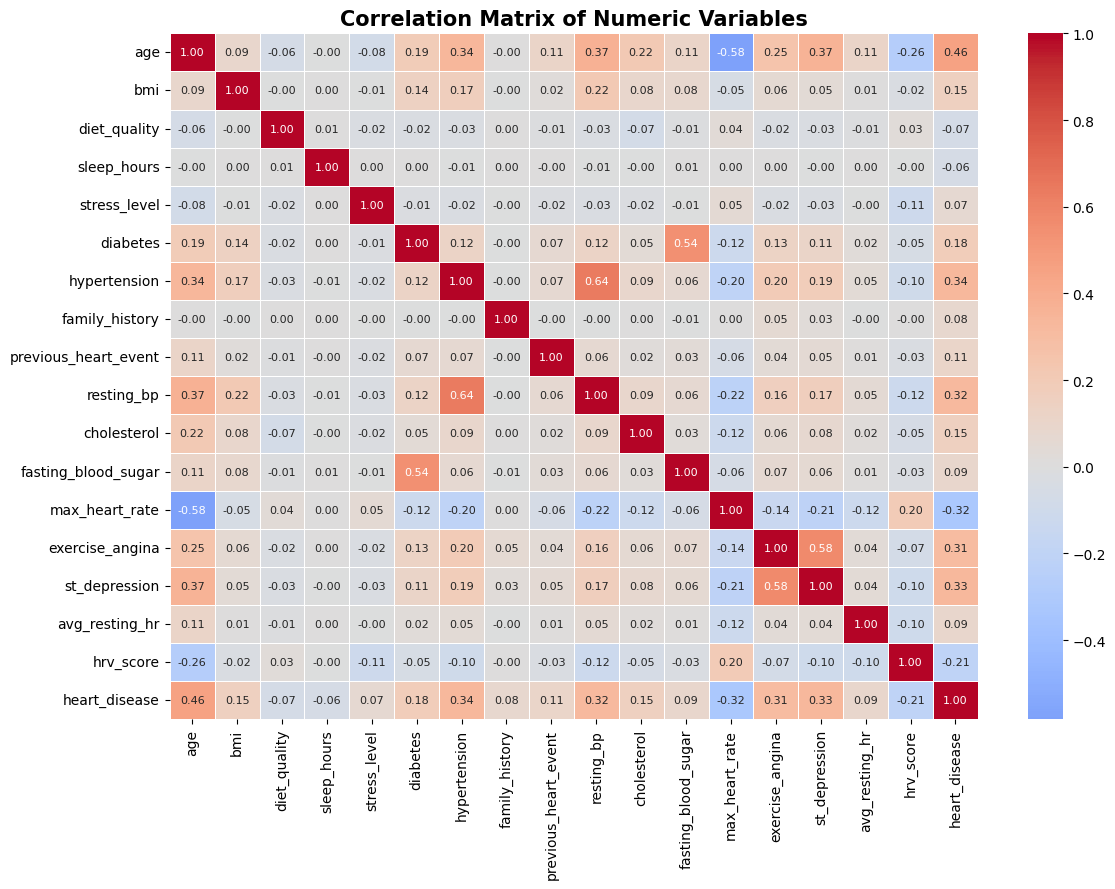

In [16]:
import seaborn as sns

# Correlation between all numeric columns (18 columns, including heart_disease)
corr = df.select_dtypes("number").corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, annot_kws={"size": 8})   # annot=True writes the number in each cell
plt.grid(False)                                      # remove the grid lines from the global style
plt.title("Correlation Matrix of Numeric Variables", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Figure 4.** Correlation Matrix of Numeric Variables

The strongest correlations with heart disease are moderate (age r = 0.46; hypertension, ST depression, resting blood pressure, maximum heart rate and exercise-induced angina |r| = 0.31-0.34), and the numeric lifestyle variables are only weakly correlated (|r| ≤ 0.07). No single variable therefore separates patients with and without heart disease on its own, which motivates combining several variables in the models of Section IV.

### **Interaction**

Interaction means whether the effect of one factor changes depending on another factor. The question here is: **does smoking increase risk at every age, or only at some ages?** Therefore, the simplest way to check is to calculate the disease rate for each combination (age group × smoking status).

smoking_status  Never  Former  Current
age_group                             
<40              10.6    13.0     19.7
40-54            30.1    34.1     47.1
55-64            54.2    59.3     71.8
65+              76.9    80.8     87.1


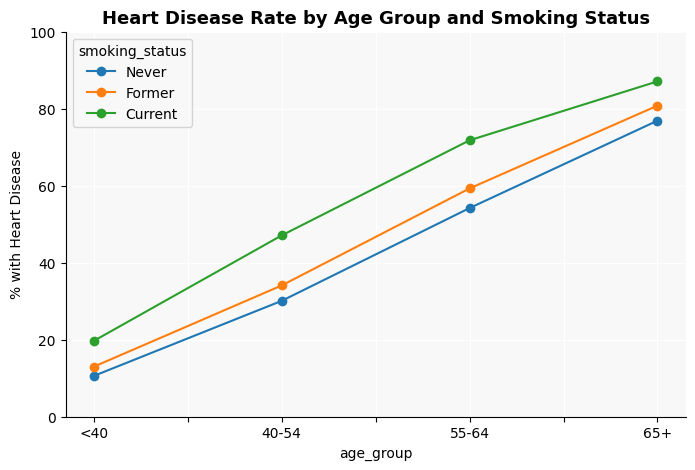

In [17]:
# Heart disease rate (%) for each combination of age group and smoking status
table = df.pivot_table(index="age_group", columns="smoking_status",
                       values="heart_disease", aggfunc="mean", observed=True) * 100
table = table[["Never", "Former", "Current"]].round(1)   # put the columns in order
print(table)

# Line chart: one line per smoking status
table.plot(kind="line", marker="o", figsize=(8, 5))
plt.ylabel("% with Heart Disease")
plt.title("Heart Disease Rate by Age Group and Smoking Status", fontweight="bold")
plt.ylim(0, 100)
plt.show()

**Figure 5.** Heart disease rates by age group and smoking status.

Heart disease rates increase across age groups for all three smoking-status categories. Within each age group, current smokers have the highest observed rate, followed by former smokers and never-smokers. The differences between smoking groups appear to vary across age groups, suggesting a possible interaction between age and smoking status.

## 3.3 Hypothesis Testing

**Verifying Hypothesis 1: Smoking vs. Heart Disease**

In [18]:
# Group smoking status into 2 categories: Smoker and Non-smoker
df["is_smoker"] = df["smoking_status"].apply(lambda x: "Smoker" if x != "Never" else "Non-smoker")

# Calculate the heart disease rate (%)
h1_table = pd.crosstab(df["is_smoker"], df["heart_disease"], normalize="index") * 100
print(h1_table.round(2))

heart_disease      0      1
is_smoker                  
Non-smoker     56.85  43.15
Smoker         49.15  50.85


The observed heart disease rate is higher among smokers (50.85%) than non-smokers (43.15%), with a difference of 7.70 percentage points. This pattern is consistent with H1. However, the comparison alone does not establish whether the difference is statistically significant. A Chi-square test is therefore conducted to examine the association between smoking status and heart disease.

In [19]:
# Chi-Square Testing
from scipy.stats import chi2_contingency

# Compare heart disease rates between smokers and non-smokers
h1_counts = pd.crosstab(df["is_smoker"], df["heart_disease"])

# Run the Chi-square test
chi2, p_value, __, __ = chi2_contingency(h1_counts)

# Display the results
print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.2e}")

if p_value < 0.05:
    print("There is a statistically significant association.")
else:
    print("There is insufficient evidence of an association.")

Chi-square statistic: 562.89
P-value: 1.98e-124
There is a statistically significant association.


Result: chi-square = 562.89, p = 1.98e-124 (far below 0.05), so the difference in heart disease rate between smokers and non-smokers is very unlikely to be due to chance.

##### **Conclusion for Hypothesis 1: Smoking Status and Heart Disease**

The observed heart disease rate was higher among smokers (50.85%) than non-smokers (43.15%), a difference of 7.70 percentage points. The Chi-square test showed a statistically significant association between smoking status and heart disease (χ² ≈ 562.89, p < 0.001). These findings support H1. Because the data are observational, this shows an association, not that smoking causes heart disease.

**Verifying Hypothesis 2: Physical activity vs. Heart Disease**

In [20]:
# Calculate the heart disease rate (%) grouped by age group and physical activity level
h2_table = df.groupby(["age_group", "physical_activity"], observed=False)["heart_disease"].mean().unstack() * 100
print(h2_table.round(2))

physical_activity  Active  Light  Sedentary  Very Active
age_group                                               
<40                 11.26  12.42      15.76        10.14
40-54               30.51  34.77      39.04        26.67
55-64               54.31  58.77      63.49        51.01
65+                 76.95  79.66      82.46        74.52


Heart disease rates decreased consistently as physical activity levels increased across all four age groups. For example, among individuals aged 40–54, the rate was 39.04% in the sedentary group, compared with 26.67% in the very active group. These findings are consistent with H₂, although the observed association does not establish causation.

In [21]:
# Test H2 separately within each age group, so that age does not distort the comparison
for g in df["age_group"].cat.categories:
    # Keep only the patients in this age group
    sub = df[df["age_group"] == g]

    # Raw counts: physical activity level x heart disease (0/1)
    ct = pd.crosstab(sub["physical_activity"], sub["heart_disease"])

    # Chi-square test; "_" means we ignore the 4th returned value (expected counts)
    chi2, p, dof, _ = chi2_contingency(ct)

    # Print one line per age group (:>6 right-aligns the group name to 6 characters)
    print(f"{g:>6}: chi-square = {chi2:.1f}, p-value = {p:.2e}")

   <40: chi-square = 54.2, p-value = 1.01e-11
 40-54: chi-square = 350.9, p-value = 9.52e-76
 55-64: chi-square = 230.4, p-value = 1.16e-49
   65+: chi-square = 98.2, p-value = 3.79e-21


Result: p-values are below 0.001 in all four age groups (largest: 1.01e-11 at <40), so activity level is significantly associated with heart disease within every age group.

##### **Conclusion for Hypothesis 2: Physical Activity and Heart Disease**

Heart disease rates decreased consistently as physical activity levels increased across all four age groups. For example, among individuals aged 40–54, the rate decreased from 39.04% in the sedentary group to 26.67% in the very active group. Chi-square tests showed statistically significant associations between physical activity and heart disease within each age group (all p-values < 0.001). These findings support H₂. However, since the data are observational, the results do not establish that physical activity directly reduces heart disease risk.

The Chi-square tests provided statistical evidence of associations between smoking status, physical activity, and heart disease in the dataset. Building on these findings, the next section applies logistic regression to further explore the relationship between selected demographic, clinical, and lifestyle factors and heart disease, while also evaluating the model's predictive performance.

# IV. Logistic Regression Model


In [22]:

import pandas as pd
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Split the data into training (80%) and test (20%) sets

# df must already contain the dataset.
# The training set is used to estimate the model coefficients.
# The test set is reserved for evaluating predictions on unseen observations.
#
# test_size=0.20 reserves 20% of the observations for testing.
# random_state=42 makes the split reproducible with the same data.
# stratify preserves approximately the same heart_disease class proportions
# in both the training and test sets.
train, test = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["heart_disease"]
)


# 2. Define and fit the logistic regression model

# Dependent variable:
# heart_disease, coded as 0 = no disease and 1 = disease.
#
# Control variables:
# age, resting_bp, and bmi.
#
# Lifestyle variables:
# sleep_hours, stress_level, diet_quality,
# smoking_status, alcohol_intake, and physical_activity.
#
# The ~ symbol separates the dependent variable from the explanatory variables.
# The + symbols add explanatory variables to the model.
# An intercept is included automatically.
#
# C() treats a variable as categorical and creates dummy variables.
# One category is omitted as the reference group.
# The remaining category coefficients are interpreted relative to that group.
#
# Numerical variables enter the model linearly in the log-odds.
# Their coefficients do not directly represent changes in probability.
formula = """
heart_disease ~ age + resting_bp + bmi
+ sleep_hours + stress_level + diet_quality
+ C(smoking_status)
+ C(alcohol_intake)
+ C(physical_activity)
"""

# Create a binary logistic regression and estimate its coefficients.
# formula=formula uses the equation defined above.
# data=train uses only the training observations.
# missing="raise" produces an error if required model variables are missing.
# fit() estimates the coefficients using maximum likelihood.
# maxiter=200 allows up to 200 optimization iterations.
# The algorithm may stop earlier if it converges.
# The fitted results are stored in model.
model = smf.logit(
    formula=formula,
    data=train,
    missing="raise"
).fit(maxiter=200)

# Display coefficients, standard errors, z-statistics, p-values,
# confidence intervals, and overall model fit statistics.
print(model.summary())

# Retrieve the convergence status from the optimization results dictionary.
# True indicates that the optimizer met its convergence criterion.
# Convergence alone does not establish model accuracy or correct specification.
print("Model converged:", model.mle_retvals["converged"])


# 3. Check multicollinearity using VIF

# Extract the actual explanatory-variable matrix used by the fitted model.
# It includes the intercept, numerical variables, and categorical dummy variables.
X = model.model.exog

# Retrieve the corresponding column names.
variable_names = model.model.exog_names

# Calculate one VIF value for each column in X.
# X.shape[1] gives the number of columns.
# The list comprehension repeats the calculation for every column.
#
# VIF measures how strongly an explanatory variable can be explained
# by the other explanatory variables.
# It does not measure association with the dependent variable.
#
# Values near 1 indicate little multicollinearity.
# Values above 5 are commonly investigated, but this is not a strict rule.
vif_table = pd.DataFrame({
    "Variable": variable_names,
    "VIF": [
        variance_inflation_factor(X, i)
        for i in range(X.shape[1])
    ]
})

# Keep the intercept in the VIF calculations, but exclude it from the report.
# We focus on the explanatory variables rather than interpreting intercept VIF.
vif_table = vif_table[vif_table["Variable"] != "Intercept"]

# Display the VIF table rounded to two decimal places.
# \n inserts a new line before the heading.
print("\nVIF results:")
print(vif_table.round(2))


# 4. Predict outcomes on the test set

# Use the fitted coefficients to calculate a probability of heart_disease=1
# for each observation in the test set.
# This does not re-estimate the model using test data.
probabilities = model.predict(test)

# Apply a classification threshold of 0.50:
# probability >= 0.50 becomes True, then integer 1.
# probability < 0.50 becomes False, then integer 0.
# The threshold is a modelling choice, not a medical diagnostic rule.
predictions = (probabilities >= 0.50).astype(int)


# 5. Evaluate model accuracy

# Store the actual outcomes from the test set.
y_test = test["heart_disease"]

# Compare predicted classes with actual classes.
# Accuracy = number of correct predictions / total number of test observations.
# round(..., 3) rounds the displayed value to three decimal places.
print("\nModel accuracy:", round(
    accuracy_score(y_test, predictions), 3
))

# Display the confusion matrix.
# labels=[0, 1] fixes the class order for both rows and columns.
# Rows represent actual classes; columns represent predicted classes.
#
# Matrix layout:
# [[True negatives,  False positives],
#  [False negatives, True positives]]
#
# False positive: predicts disease when the actual outcome is no disease.
# False negative: predicts no disease when the actual outcome is disease.
print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions, labels=[0, 1]))


# 6. Compare with always predicting the training majority class

# mode() returns the most frequent class or classes in the training set.
# iloc[0] selects the first returned value.
# The baseline predicts this same class for every test observation.
majority_class = train["heart_disease"].mode().iloc[0]

# Check which actual test outcomes match the majority class.
# The comparison produces True for matches and False for non-matches.
# mean() treats True as 1 and False as 0, giving the proportion of matches.
baseline_accuracy = (y_test == majority_class).mean()

# Display the baseline accuracy for comparison with the model accuracy.
# This helps determine whether the model improves on a simple constant prediction.
print("\nMajority-class baseline accuracy:", round(
    baseline_accuracy, 3
))


Optimization terminated successfully.
         Current function value: 0.534407
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:          heart_disease   No. Observations:                80000
Model:                          Logit   Df Residuals:                    79986
Method:                           MLE   Df Model:                           13
Date:                Sun, 01 Nov 2026   Pseudo R-squ.:                  0.2256
Time:                        13:19:32   Log-Likelihood:                -42753.
converged:                       True   LL-Null:                       -55206.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                              -7.0985      0.102 

## Interpretation of the Model

- The logistic regression model converged successfully using 80,000 training observations. The overall model is statistically significant, indicating an improvement over the intercept-only model. The LLR p-value is smaller than 0.05.

  **LLR Test Hypotheses:**
  - H0: All independent variable coefficients are equal to zero.
  - H1: At least one independent variable coefficient is different from zero.

  Since the LLR p-value is smaller than 0.05, we reject H0. Therefore, the model is statistically significant overall.

- All independent variable coefficients and the intercept have p-values smaller than 0.05. Therefore, they are statistically significant at the 5% significance level.

- All VIF values are below 5, indicating no evidence of serious multicollinearity in the model.

- On the test set of 20,000 observations, the model achieved 73.1% accuracy, compared with 53.9% for the majority-class baseline. At the 0.50 classification threshold, the model correctly identified 6,418 of the 9,216 patients with heart disease (recall ≈ 69.6%). There were 2,575 false positives and 2,798 false negatives.

### Interpretation of Independent Variables

In logistic regression, the odds ratio (OR) is calculated as:

**OR = e^β**

**Percentage change in odds = (e^β − 1) × 100**

All interpretations are made while holding the other variables constant.

- **Age:** The coefficient is 0.0859. A one-year increase in age is associated with approximately 8.9697% higher odds of heart disease.

- **Resting blood pressure:** The coefficient is 0.0156. A 1 mmHg increase in resting blood pressure is associated with approximately 1.5722% higher odds of heart disease.

- **BMI:** The coefficient is 0.0431. A one-unit increase in BMI is associated with approximately 4.4042% higher odds of heart disease.

- **Sleep hours:** The coefficient is −0.1590. One additional hour of sleep is associated with approximately 14.7004% lower odds of heart disease.

- **Stress level:** The coefficient is 0.1377. A one-point increase in stress level is associated with approximately 14.7631% higher odds of heart disease.

- **Diet quality:** The coefficient is −0.0451. A one-point increase in diet quality is associated with approximately 4.4098% lower odds of heart disease.

- **Former smokers:** The coefficient is −0.4436. Former smokers have approximately 35.8278% lower odds of heart disease compared to current smokers.

- **Never smokers:** The coefficient is −0.6873. Individuals who have never smoked have approximately 49.7068% lower odds of heart disease compared to current smokers.

- **Moderate drinkers:** The coefficient is −0.1468. Moderate drinkers have approximately 13.6533% lower odds of heart disease compared to heavy drinkers.

- **Non-drinkers:** The coefficient is −0.2693. Non-drinkers have approximately 23.6086% lower odds of heart disease compared to heavy drinkers.

- **Light physical activity:** The coefficient is 0.1829. Participants with light physical activity have approximately 20.0694% higher odds of heart disease compared to active participants.

- **Sedentary:** The coefficient is 0.3806. Sedentary participants have approximately 46.3162% higher odds of heart disease compared to active participants.

- **Very active:** The coefficient is −0.1517. Very active participants have approximately 14.0754% lower odds of heart disease compared to active participants.

**Note:** "Heart-rate variables were excluded to keep the model simple and focus on lifestyle factors while controlling for age, resting blood pressure, and BMI. Including maximum heart rate, average resting heart rate, and heart rate reserve together would cause perfect multicollinearity, because heart rate reserve is calculated as maximum heart rate minus average resting heart rate."

## **Predicting Risk Score**


In [ ]:
###### import pandas as pd

# Collect numerical inputs


age = float(input("Age: "))

if age < 29:
    age = 29
    print("Age adjusted to 29 for the model calculation.")
bmi = float(input("Body Mass Index"))
resting_bp = float(input("Resting blood pressure (mmHg): "))
sleep_hours = float(input("Sleep per night (hours): "))
stress_level = float(input("Stress level (1–10): "))
diet_quality = float(input("Diet quality (1–10): "))

# Show the exact category labels used in the training data
categories = [
    "smoking_status",
    "alcohol_intake",
    "physical_activity"
]

user_categories = {}

for column in categories:
    options = sorted(train[column].dropna().unique())
    print(f"\n{column} options: {', '.join(options)}")

    answer = input("Enter one option exactly as shown: ").strip()

    while answer not in options:
        answer = input("Invalid option. Please try again: ").strip()

    user_categories[column] = answer

# Create a one-row table with the same variable names as the model
user_data = pd.DataFrame({
    "age": [age],
    "resting_bp": [resting_bp],
    "sleep_hours": [sleep_hours],
    "stress_level": [stress_level],
    "diet_quality": [diet_quality],
    "smoking_status": [user_categories["smoking_status"]],
    "alcohol_intake": [user_categories["alcohol_intake"]],
    "physical_activity": [user_categories["physical_activity"]]
})

# Check basic input validity
if not (
    0 < age < 120
    and resting_bp > 0
    and 0 <= sleep_hours <= 24
    and 1 <= stress_level <= 10
    and 1 <= diet_quality <= 10
):
    print("Invalid numerical input. Please check your answers.")

else:
    # Avoid predictions outside the numerical ranges seen in training
    numerical_columns = [
        "age", "resting_bp", "sleep_hours",
        "stress_level", "diet_quality"
    ]

    outside_range = [
        column for column in numerical_columns
        if not (
            train[column].min()
            <= user_data[column].iloc[0]
            <= train[column].max()
        )
    ]

    if outside_range:
        print("Outside the training data range:", outside_range)
        print("No score displayed.")

    else:
        probability = model.predict(user_data).iloc[0]
        score = probability * 100

        print(f"\nEducational model score: {score:.1f}/100")
        print(
            "Based on synthetic data. "
            "This is not a validated personal medical risk estimate. If you think you have a medical problem please see a doctor."
        )


smoking_status options: Current, Former, Never

alcohol_intake options: Heavy, Moderate, Non-drinker


## V. Heart Health Insight App
### 5.1. Design

- The app is a desktop form made with Tkinter. It asks for age, smoking status, and physical activity. A button displays heart disease percentages for smoking and activity categories within the selected age band. Sample sizes appear beside every percentage. A reset button clears the form. Invalid ages display a message box.

- The interface follows the teacher's example: create a window with tk.Tk(), set its title and size, and give it a light blue background. Labels explain the fields, Entry collects age, OptionMenu provides category choices, and Button calls a function. The code uses functions, if/elif/else, for loops, and pandas filtering.

### Running the app
- Open heart_health_tkinter.py in your local Python editor and run it. Keep heart_disease_prediction_2026.csv in the same folder. Your Python environment needs pandas and Tkinter. Tkinter requires a local desktop; Google Colab cannot display this window directly.

In [ ]:
"""Run this file on your computer to open the Heart Health Insights window."""
import tkinter as tk
from tkinter import messagebox
from pathlib import Path
import pandas as pd


def show_results():
    # Read the text entered by the user and check that the age is valid.
    age_text = age_entry.get().strip()
    if not age_text.isdigit():
        messagebox.showerror("Invalid age", "Please enter your age as a whole number.")
        return

    age = int(age_text)
    if age < 29 or age > 80:
        messagebox.showerror("Age outside dataset", "Please enter an age from 29 to 80, the range in our dataset.")
        return

    # Use the same age groups as the project analysis.
    if age < 40:
        minimum, maximum = 29, 39
    elif age < 55:
        minimum, maximum = 40, 54
    elif age < 65:
        minimum, maximum = 55, 64
    else:
        minimum, maximum = 65, 80

    smoking = smoking_choice.get()
    activity = activity_choice.get()
    peers = data[(data["age"] >= minimum) & (data["age"] <= maximum)]

    # The mean of a 0/1 column is the proportion with heart disease.
    report = f"Age group: {minimum}-{maximum}\n"
    report += f"Your selections: {smoking}; {activity}\n\n"
    report += "SMOKING STATUS\n"
    for category in ["Never", "Former", "Current"]:
        group = peers[peers["smoking_status"] == category]
        if len(group) > 0:
            rate = group["heart_disease"].mean() * 100
            marker = "  <-- selected" if category == smoking else ""
            report += f"{category}: {rate:.1f}% ({len(group):,} records){marker}\n"
        else:
            report += f"{category}: no records\n"

    report += "\nPHYSICAL ACTIVITY\n"
    for category in ["Sedentary", "Light", "Active", "Very Active"]:
        group = peers[peers["physical_activity"] == category]
        if len(group) > 0:
            rate = group["heart_disease"].mean() * 100
            marker = "  <-- selected" if category == activity else ""
            report += f"{category}: {rate:.1f}% ({len(group):,} records){marker}\n"
        else:
            report += f"{category}: no records\n"

    report += "\nEach table compares one factor within your age group.\n"
    report += "These are separate comparisons, not a matched personal profile.\n\n"
    report += "This project treats the data as synthetic teaching data.\n"
    report += "Percentages describe this dataset, not your personal risk.\n"
    report += "Other factors may explain differences between categories.\n"
    report += "For personal prevention advice, consult a healthcare professional."
    results_box.config(state="normal")
    results_box.delete("1.0", tk.END)
    results_box.insert(tk.END, report)
    results_box.config(state="disabled")


def reset_form():
    age_entry.delete(0, tk.END)
    smoking_choice.set("Never")
    activity_choice.set("Sedentary")
    results_box.config(state="normal")
    results_box.delete("1.0", tk.END)
    results_box.insert(
        tk.END,
        "Your dataset comparisons will appear here."
    )
    results_box.config(state="disabled")

if __name__ == "__main__":
    # Keep the CSV beside this Python file.
    if "__file__" in globals():
        csv_path = Path(__file__).with_name("heart_disease_prediction_2026.csv")
    else:
        csv_path = Path("heart_disease_prediction_2026.csv")

    # Create the main window, following the class example.
    window = tk.Tk()
    window.title("Heart Health Insights App")
    window.geometry("850x780")
    window.configure(bg="lightblue")

    try:
        data = pd.read_csv(csv_path)
    except (OSError, pd.errors.ParserError) as error:
        messagebox.showerror("Dataset could not be loaded", str(error))
        window.destroy()
    else:
        tk.Label(window, text="Heart Health Insights App", font=("Arial", 20, "bold"), bg="lightblue").pack(pady=12)
        tk.Label(window, text="Explore smoking and activity categories in the dataset.", bg="lightblue").pack()

        tk.Label(window, text="Enter your age (29-80)", bg="lightblue").pack(pady=(12, 2))
        age_entry = tk.Entry(window, width=20)
        age_entry.pack()

        tk.Label(window, text="Smoking status", bg="lightblue").pack(pady=(8, 2))
        smoking_choice = tk.StringVar(value="Never")
        tk.OptionMenu(window, smoking_choice, "Never", "Former", "Current").pack()

        tk.Label(window, text="Physical activity", bg="lightblue").pack(pady=(8, 2))
        activity_choice = tk.StringVar(value="Sedentary")
        tk.OptionMenu(window, activity_choice, "Sedentary", "Light", "Active", "Very Active").pack()

        buttons = tk.Frame(window, bg="lightblue")
        buttons.pack(pady=12)
        tk.Button(buttons, text="Show insights", command=show_results).pack(side=tk.LEFT, padx=5)
        tk.Button(buttons, text="Reset", command=reset_form).pack(side=tk.LEFT, padx=5)


        # Create a scrollable results area
        results_frame = tk.Frame(window)
        results_frame.pack(
            fill="both",
            expand=True,
            padx=15,
            pady=(0, 15)
        )

        scrollbar = tk.Scrollbar(results_frame)
        scrollbar.pack(side=tk.RIGHT, fill=tk.Y)

        results_box = tk.Text(
            results_frame,
            wrap="word",
            font=("Arial", 12),
            padx=12,
            pady=12,
            yscrollcommand=scrollbar.set
        )

        results_box.pack(side=tk.LEFT, fill="both", expand=True)

        scrollbar.config(command=results_box.yview)

        results_box.insert(
            tk.END,
            "Your dataset comparisons will appear here."
        )

        results_box.config(state="disabled")
        window.mainloop()

### 5.2. Demo
1. Enter age 45, choose Current and Sedentary, then click Show insights.
2. Explain that Current smokers in the 40–54 age group have a dataset disease rate of 47.1%, compared with 30.1% for Never smokers.
3. Explain that each table compares a separate factor. These are not individually matched records or a personal prediction.
4. Enter an invalid age to demonstrate the message box.
5. Click Reset to clear the form.


In [ ]:
import tkinter as tk
from tkinter import messagebox
import pandas as pd


# 1. Load the dataset
# Keep the CSV in the same folder as this notebook.
data = pd.read_csv("heart_disease_prediction_2026.csv")


# 2. Create the function for the Show Insights button
def show_results():

    # Check the age entered by the user
    age_text = age_entry.get().strip()

    if not age_text.isdigit():
        messagebox.showerror(
            "Invalid age",
            "Please enter your age as a whole number."
        )
        return

    age = int(age_text)

    if age < 29 or age > 80:
        messagebox.showerror(
            "Age outside dataset",
            "Please enter an age between 29 and 80."
        )
        return

    # Select the age group
    if age < 40:
        minimum = 29
        maximum = 39
    elif age < 55:
        minimum = 40
        maximum = 54
    elif age < 65:
        minimum = 55
        maximum = 64
    else:
        minimum = 65
        maximum = 80

    # Read the selected categories
    smoking = smoking_choice.get()
    activity = activity_choice.get()

    # Keep records within the selected age group
    age_data = data[
        (data["age"] >= minimum) &
        (data["age"] <= maximum)
    ]

    # Start the results message
    report = "HEART HEALTH INSIGHTS\n\n"
    report += f"Age group: {minimum}–{maximum}\n"
    report += f"Smoking status: {smoking}\n"
    report += f"Physical activity: {activity}\n\n"

    report += "Percentages show records with heart disease.\n"
    report += "Each comparison uses the selected age group.\n\n"

    # Compare smoking categories
    report += "SMOKING STATUS\n"

    for category in ["Never", "Former", "Current"]:

        group = age_data[
            age_data["smoking_status"] == category
        ]

        if len(group) > 0:
            # The mean of a 0/1 column gives the proportion.
            rate = group["heart_disease"].mean() * 100

            report += (
                f"{category}: {rate:.1f}% "
                f"({len(group):,} records)"
            )

            if category == smoking:
                report += "  ← Your selection"

            report += "\n"

        else:
            report += f"{category}: no records\n"

    # Compare physical activity categories
    report += "\nPHYSICAL ACTIVITY\n"

    for category in [
        "Sedentary", "Light", "Active", "Very Active"
    ]:

        group = age_data[
            age_data["physical_activity"] == category
        ]

        if len(group) > 0:
            rate = group["heart_disease"].mean() * 100

            report += (
                f"{category}: {rate:.1f}% "
                f"({len(group):,} records)"
            )

            if category == activity:
                report += "  ← Your selection"

            report += "\n"

        else:
            report += f"{category}: no records\n"

    # Explain how to interpret the results
    report += "\nHOW TO READ THESE RESULTS\n"
    report += "Smoking and activity are compared separately.\n"
    report += "The groups are not an exact match for you.\n"
    report += "Other factors may explain the differences.\n\n"

    report += "This project treats the dataset as synthetic.\n"
    report += "These percentages are not your personal risk "
    report += "or a medical diagnosis.\n"
    report += "For personal prevention advice, speak with "
    report += "a healthcare professional."

    # Display the report in the results area
    results_box.config(state="normal")
    results_box.delete("1.0", tk.END)
    results_box.insert(tk.END, report)
    results_box.config(state="disabled")


# 3. Create the function for the Reset button
def reset_form():

    age_entry.delete(0, tk.END)
    smoking_choice.set("Never")
    activity_choice.set("Sedentary")

    results_box.config(state="normal")
    results_box.delete("1.0", tk.END)
    results_box.insert(
        tk.END,
        "Your dataset comparisons will appear here."
    )
    results_box.config(state="disabled")

    age_entry.focus_set()


# 4. Create the main window
window = tk.Tk()
window.title("Heart Health Insights App")
window.geometry("800x800")
window.configure(bg="lightblue")


# 5. Add the title and introduction
title_label = tk.Label(
    window,
    text="Heart Health Insights App",
    font=("Arial", 22, "bold"),
    bg="lightblue"
)
title_label.pack(pady=12)

intro_label = tk.Label(
    window,
    text="Explore smoking and physical activity in our dataset.",
    font=("Arial", 12),
    bg="lightblue"
)
intro_label.pack(pady=5)


# 6. Add the age input
age_label = tk.Label(
    window,
    text="Enter your age (29–80):",
    bg="lightblue"
)
age_label.pack(pady=(10, 3))

age_entry = tk.Entry(window, width=20)
age_entry.pack()


# 7. Add the smoking menu
smoking_label = tk.Label(
    window,
    text="Smoking status:",
    bg="lightblue"
)
smoking_label.pack(pady=(10, 3))

smoking_choice = tk.StringVar(window)
smoking_choice.set("Never")

smoking_menu = tk.OptionMenu(
    window,
    smoking_choice,
    "Never",
    "Former",
    "Current"
)
smoking_menu.pack()


# 8. Add the physical activity menu
activity_label = tk.Label(
    window,
    text="Physical activity:",
    bg="lightblue"
)
activity_label.pack(pady=(10, 3))

activity_choice = tk.StringVar(window)
activity_choice.set("Sedentary")

activity_menu = tk.OptionMenu(
    window,
    activity_choice,
    "Sedentary",
    "Light",
    "Active",
    "Very Active"
)
activity_menu.pack()


# 9. Add the buttons
button_frame = tk.Frame(window, bg="lightblue")
button_frame.pack(pady=12)

show_button = tk.Button(
    button_frame,
    text="Show Insights",
    command=show_results
)
show_button.pack(side=tk.LEFT, padx=5)

reset_button = tk.Button(
    button_frame,
    text="Reset",
    command=reset_form
)
reset_button.pack(side=tk.LEFT, padx=5)


# 10. Add a scrollable results area
results_frame = tk.Frame(window)
results_frame.pack(
    fill=tk.BOTH,
    expand=True,
    padx=15,
    pady=(0, 15)
)

scrollbar = tk.Scrollbar(results_frame)
scrollbar.pack(side=tk.RIGHT, fill=tk.Y)

results_box = tk.Text(
    results_frame,
    wrap="word",
    font=("Arial", 12),
    padx=12,
    pady=12,
    yscrollcommand=scrollbar.set
)
results_box.pack(side=tk.LEFT, fill=tk.BOTH, expand=True)

scrollbar.config(command=results_box.yview)

results_box.insert(
    tk.END,
    "Your dataset comparisons will appear here."
)
results_box.config(state="disabled")


# 11. Keep the window open
window.mainloop()

## **VI. Conclusion**

### **6.1 Key findings**

**Research question: Which factors are most strongly associated with heart disease?**

The exploratory analysis identified several demographic, clinical, and lifestyle factors that showed notable associations with heart disease in this dataset.

- Age: Age showed one of the clearest associations with heart disease. The observed heart disease rate increased substantially across age groups, from 12.5% among individuals under 40 to 79.3% among those aged 65 and above.

- Clinical measurements: Individuals with heart disease had higher mean resting systolic blood pressure (150.80 vs. 134.60 mmHg), cholesterol levels (225.58 vs. 210.91 mg/dL), and ST depression values (1.77 vs. 1.07). They also had lower mean maximum heart rate (169.15 vs. 178.61 bpm) and HRV score (48.47 vs. 56.48).

- Lifestyle factors: The observed heart disease rate was higher among current smokers (57.4%) than never-smokers (43.1%). A decreasing pattern was also observed across physical activity categories, from 53.1% among sedentary individuals to 38.4% among very active individuals. Furthermore, hypothesis testing showed a statistically significant association between smoking status and heart disease, with a 7.70 percentage-point difference between the combined smoker group (Former and Current smokers) and non-smokers. Physical activity also showed statistically significant associations with heart disease across all four age groups.

- Other categorical patterns: Heart disease rates increased across the defined blood pressure categories, from 24.4% in the Normal category to 59.2% in the High (stage 2) category. Rates also varied across resting ECG and ST slope categories, indicating differences in heart disease prevalence across these groups.

Overall, age, clinical measurements, smoking status, and physical activity showed notable differences in relation to heart disease. The exploratory analysis and hypothesis tests provided complementary perspectives on these patterns. However, all findings describe associations within the dataset and do not establish causal relationships.

### **6.2. Logistic Regression Model Performance**

The logistic regression model examined how age, resting blood pressure, BMI, sleep duration, stress level, diet quality, smoking status, alcohol intake, and physical activity were associated with heart disease. Including these variables together allowed each association to be evaluated while holding the other included predictors constant.

The model achieved 73.1% accuracy on the test set, outperforming the majority-class baseline accuracy of 53.9%. It also achieved a recall of approximately 69.6%, correctly identifying 6,418 out of 9,216 observations with heart disease. These results suggest that the selected predictors provide useful information for distinguishing between the two target classes within this synthetic dataset.

However, the model's predictive performance should be interpreted cautiously, as it has not been validated using real-world clinical data.

### **6.3 Practical Insights and Application**

The exploratory analysis highlights several patterns that may be useful for further investigation. Age and clinical measurements showed clear differences between individuals with and without heart disease in this dataset. Smoking status and physical activity also displayed notable differences in observed heart disease rates.

In addition, the interactive Heart Health Insight App provides an accessible way to explore heart disease rates across smoking and physical activity categories within different age groups. Rather than generating individual predictions, the application allows users to examine patterns in the dataset.

These findings and the application demonstrate how Python-based data analysis and visualization can support the exploration of health-related datasets. However, the results should not be interpreted as direct medical recommendations. Further validation using real-world clinical data would be necessary before applying these findings in practice.

### **6.4 Limitations**

Despite the findings, this project has several limitations that should be considered when interpreting the results.

- Synthetic data: The dataset documentation describes a calibrated data-generation process. Therefore, the observed patterns may reflect the assumptions and relationships built into the generation process and cannot automatically be generalized to real-world populations.

- Association, not causation: The analyses identify associations between variables and heart disease status. They do not establish that smoking, physical inactivity, or other factors directly cause heart disease.

- Potential confounding: Several predictors are correlated with each other, such as age and maximum heart rate (r = -0.58). Although some comparisons were examined within age groups, other potential confounding factors were not fully controlled for.

- Limitations of statistical analysis: The EDA relies mainly on descriptive comparisons and selected statistical tests. These analyses do not fully account for the joint effects of all predictors.

- Statistical significance versus practical importance: With 100,000 records, small differences may produce very small p-values. Effect sizes and the practical importance of the differences should therefore be considered alongside statistical significance.

- Predictive model limitations: The logistic regression model uses a selected set of predictors and a fixed classification threshold of 0.50. Its performance was evaluated using a single train-test split, so the reported metrics may vary with different data splits or classification thresholds. Further evaluation, including cross-validation and calibration assessment, would provide a more comprehensive understanding of model performance.

- Not a medical tool: The predictive model and interactive application are intended for educational and exploratory purposes only. Neither has been validated using real-world clinical data, and their outputs should not be interpreted as reliable estimates of an individual's personal heart disease risk.